# 02 · Exploratory Data Analysis — PCOS Prediction

**Input:** `data/processed/pcos_clean.csv` (produced by `01_data_audit_and_cleaning.ipynb`)

**Questions we want to answer**
1. What does the data look like (size, types, feature groups)?
2. What is the target and how balanced is it?
3. How is each feature distributed (skew, shape)?
4. Where are the outliers?
5. Which features differ between PCOS and non-PCOS patients?
6. How are features correlated with the target and with each other?

## 1. Setup

In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60, "display.width", 200, "display.float_format", "{:,.3f}".format)

ROOT = Path.cwd().parent
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
PAL = {0: "#4c8bc4", 1: "#e0663d"}          # 0 = No PCOS, 1 = PCOS
LABEL = {0: "No PCOS", 1: "PCOS"}
TARGET = "pcos"

def savefig(name):
    plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

df = pd.read_csv(ROOT / "data" / "processed" / "pcos_clean.csv")

## 2. Dataset overview

In [2]:
print(f"Rows: {df.shape[0]}   Columns: {df.shape[1]}  (1 target + {df.shape[1]-1} features)")
print("Missing cells:", int(df.isna().sum().sum()))
df.info()

Rows: 541   Columns: 42  (1 target + 41 features)
Missing cells: 0
<class 'pandas.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 42 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   pcos               541 non-null    int64  
 1   age_yrs            541 non-null    int64  
 2   weight_kg          541 non-null    float64
 3   height_cm          541 non-null    float64
 4   bmi                541 non-null    float64
 5   blood_group        541 non-null    int64  
 6   pulse_rate_bpm     541 non-null    int64  
 7   resp_rate          541 non-null    int64  
 8   hb_g_dl            541 non-null    float64
 9   cycle_ri           541 non-null    int64  
 10  cycle_length_days  541 non-null    int64  
 11  marriage_yrs       541 non-null    float64
 12  pregnant           541 non-null    int64  
 13  n_abortions        541 non-null    int64  
 14  beta_hcg_1         541 non-null    float64
 15  beta_hcg_2        

In [3]:
df.head()

,pcos,age_yrs,weight_kg,height_cm,bmi,blood_group,pulse_rate_bpm,resp_rate,hb_g_dl,cycle_ri,cycle_length_days,marriage_yrs,pregnant,n_abortions,beta_hcg_1,beta_hcg_2,fsh,lh,fsh_lh_ratio,hip_inch,waist_inch,waist_hip_ratio,tsh,amh,prl,vit_d3,prg,rbs,weight_gain,hair_growth,skin_darkening,hair_loss,pimples,fast_food,reg_exercise,bp_systolic,bp_diastolic,follicle_l,follicle_r,avg_f_size_l,avg_f_size_r,endometrium
0,0,28,44.600,152.000,19.300,15,78,22,10.480,2,5,7.000,0,0,1.990,1.990,7.950,3.680,2.160,36,30,0.830,0.680,2.070,45.160,17.100,0.570,92.000,0,0,0,0,0,1,0,110,80,3,3,18.000,18.000,8.500
1,0,36,65.000,161.500,24.900,15,74,20,11.700,2,5,11.000,1,0,60.800,1.990,6.730,1.090,6.170,38,32,0.840,3.160,1.530,20.090,61.300,0.970,92.000,0,0,0,0,0,0,0,120,70,3,5,15.000,14.000,3.700
2,1,33,68.800,165.000,25.300,11,72,18,11.800,2,5,10.000,1,0,494.080,494.080,5.540,0.880,6.300,40,36,0.900,2.540,6.630,10.520,49.700,0.360,84.000,0,0,0,1,1,1,0,120,80,13,15,18.000,20.000,10.000
3,0,37,65.000,148.000,29.700,13,72,20,12.000,2,5,4.000,0,0,1.990,1.990,8.060,2.360,3.420,42,36,0.860,16.410,1.220,36.900,33.400,0.360,76.000,0,0,0,0,0,0,0,120,70,2,2,15.000,14.000,7.500
4,0,25,52.000,161.000,20.100,11,72,18,10.000,2,5,1.000,1,0,801.450,801.450,3.980,0.900,4.420,37,30,0.810,3.570,2.260,30.090,43.800,0.380,84.000,0,0,0,1,0,0,0,120,80,3,4,16.000,14.000,7.000


### 2.1 Feature groups
Features are split by what they *are*, since the right plot differs by type:
- **Binary flags** (0/1: symptoms & lifestyle)
- **Categorical codes** (`blood_group`, `cycle_ri` — numbers that are labels, not quantities)
- **Numeric** (measurements, hormones, ultrasound)

In [4]:
binary_cols = [c for c in df.columns if c != TARGET and df[c].nunique() == 2]
cat_cols = ["blood_group", "cycle_ri"]
num_cols = [c for c in df.columns if c not in binary_cols + cat_cols + [TARGET]]

groups = {
    "Binary flags": binary_cols, "Categorical codes": cat_cols, "Numeric": num_cols,
}
for g, cols in groups.items():
    print(f"{g} ({len(cols)}): {cols}\n")

Binary flags (8): ['pregnant', 'weight_gain', 'hair_growth', 'skin_darkening', 'hair_loss', 'pimples', 'fast_food', 'reg_exercise']

Categorical codes (2): ['blood_group', 'cycle_ri']

Numeric (31): ['age_yrs', 'weight_kg', 'height_cm', 'bmi', 'pulse_rate_bpm', 'resp_rate', 'hb_g_dl', 'cycle_length_days', 'marriage_yrs', 'n_abortions', 'beta_hcg_1', 'beta_hcg_2', 'fsh', 'lh', 'fsh_lh_ratio', 'hip_inch', 'waist_inch', 'waist_hip_ratio', 'tsh', 'amh', 'prl', 'vit_d3', 'prg', 'rbs', 'bp_systolic', 'bp_diastolic', 'follicle_l', 'follicle_r', 'avg_f_size_l', 'avg_f_size_r', 'endometrium']



## 3. Target variable: `pcos`

,class,count,percent
0,No PCOS,364,67.283
1,PCOS,177,32.717


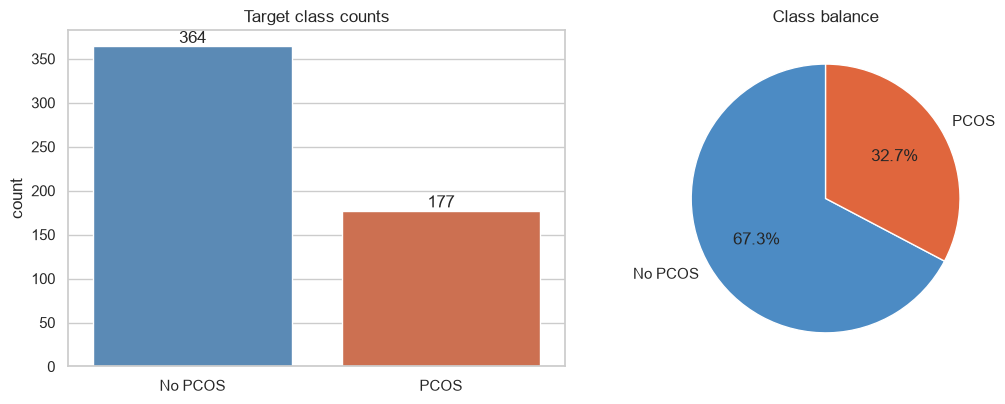

Imbalance ratio (majority/minority): 2.06 : 1


In [5]:
vc = df[TARGET].value_counts().sort_index()
pct = df[TARGET].value_counts(normalize=True).sort_index() * 100
display(pd.DataFrame({"class": [LABEL[i] for i in vc.index], "count": vc.values, "percent": pct.values}))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
sns.countplot(x=df[TARGET].map(LABEL), palette=[PAL[0], PAL[1]], ax=axes[0], order=["No PCOS", "PCOS"])
for p in axes[0].patches:
    axes[0].annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")
axes[0].set_title("Target class counts"); axes[0].set_xlabel("")
axes[1].pie(vc.values, labels=[LABEL[i] for i in vc.index], autopct="%1.1f%%", colors=[PAL[0], PAL[1]], startangle=90,
            wedgeprops={"edgecolor": "white"})
axes[1].set_title("Class balance")
plt.tight_layout(); savefig("03_target_distribution"); plt.show()
print(f"Imbalance ratio (majority/minority): {vc.max()/vc.min():.2f} : 1")

**Takeaway:** about one-third of patients have PCOS (≈ 2 : 1 imbalance). It's moderate — accuracy alone can be misleading
(always predicting "No PCOS" gives ≈ 67 %), so we use stratified splits and judge models with **AUC, precision, recall, F1 and MCC** as well.

## 4. Summary statistics

In [6]:
desc = df[num_cols].describe().T
desc["skew"] = df[num_cols].skew()
desc["kurtosis"] = df[num_cols].kurt()
desc["cv_%"] = desc["std"] / desc["mean"].replace(0, np.nan) * 100
desc

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis,cv_%
age_yrs,541.000,31.431,5.411,20.000,28.000,31.000,35.000,48.000,0.354,-0.149,17.216
weight_kg,541.000,59.637,11.028,31.000,52.000,59.000,65.000,108.000,0.515,1.174,18.492
height_cm,541.000,156.485,6.034,137.000,152.000,156.000,160.000,180.000,0.325,0.339,3.856
bmi,541.000,24.308,4.055,12.400,21.600,24.200,26.600,38.900,0.271,0.878,16.683
pulse_rate_bpm,541.000,73.457,2.686,70.000,72.000,72.000,74.000,82.000,1.249,0.673,3.657
resp_rate,541.000,19.244,1.689,16.000,18.000,18.000,20.000,28.000,1.234,2.707,8.775
hb_g_dl,541.000,11.160,0.867,8.500,10.500,11.000,11.700,14.800,0.744,0.886,7.768
cycle_length_days,541.000,4.941,1.492,0.000,4.000,5.000,5.000,12.000,0.827,4.326,30.198
marriage_yrs,541.000,7.680,4.799,0.000,4.000,7.000,10.000,30.000,1.144,1.879,62.496
n_abortions,541.000,0.288,0.693,0.000,0.000,0.000,0.000,5.000,2.971,10.190,240.182


In [7]:
skewed = desc.loc[desc["skew"].abs() > 1, "skew"].sort_values(ascending=False)
print(f"{len(skewed)} of {len(num_cols)} numeric features are strongly skewed (|skew| > 1):")
print(skewed.round(2).to_string())

16 of 31 numeric features are strongly skewed (|skew| > 1):
prg              20.730
fsh_lh_ratio     19.110
vit_d3           16.440
beta_hcg_2       12.810
tsh               9.790
fsh               8.940
beta_hcg_1        7.520
rbs               5.490
amh               3.300
n_abortions       2.970
prl               2.440
lh                1.660
pulse_rate_bpm    1.250
resp_rate         1.230
marriage_yrs      1.140
avg_f_size_l     -1.150


## 5. Distributions of numeric features

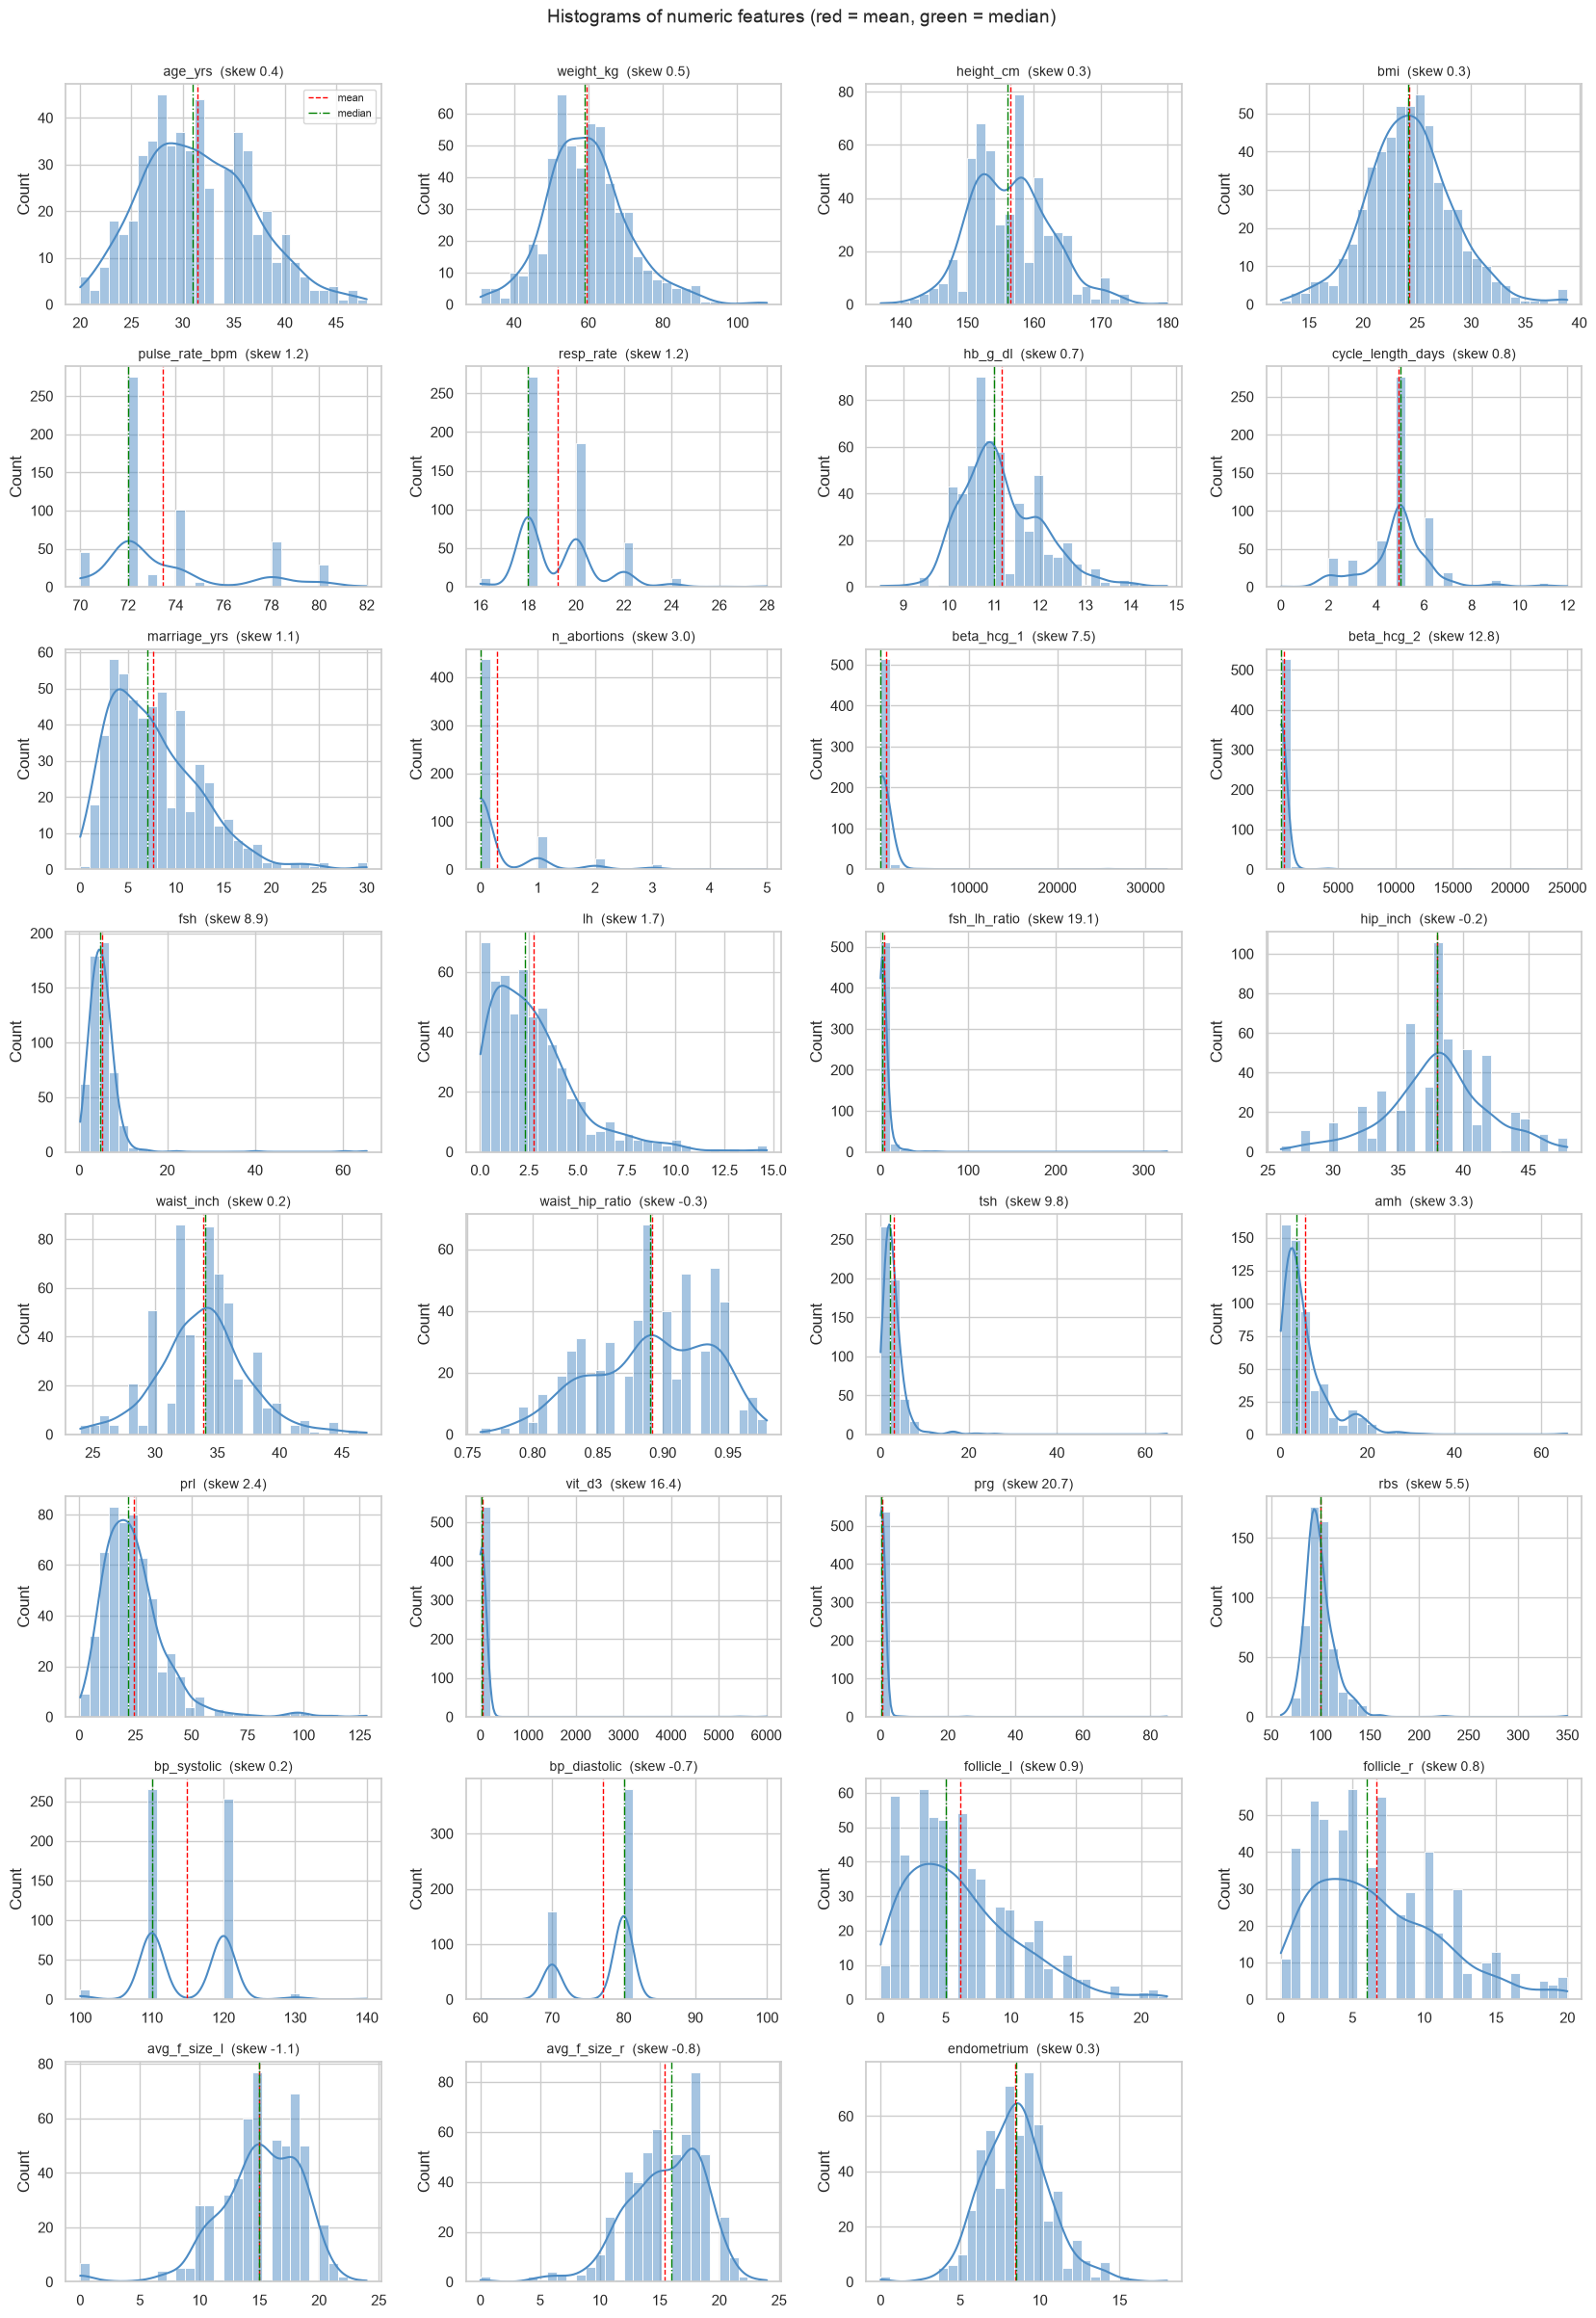

In [8]:
def grid(n, ncols=4, h=3.0):
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, h * nrows))
    axes = np.array(axes).ravel()
    for ax in axes[n:]: ax.axis("off")
    return fig, axes

fig, axes = grid(len(num_cols))
for ax, col in zip(axes, num_cols):
    sns.histplot(df[col], kde=True, bins=30, color="#4c8bc4", ax=ax)
    ax.axvline(df[col].mean(), color="red", ls="--", lw=1, label="mean")
    ax.axvline(df[col].median(), color="green", ls="-.", lw=1, label="median")
    ax.set_title(f"{col}  (skew {df[col].skew():.1f})", fontsize=10); ax.set_xlabel("")
axes[0].legend(fontsize=8)
fig.suptitle("Histograms of numeric features (red = mean, green = median)", y=1.002, fontsize=14)
plt.tight_layout(); savefig("04_numeric_histograms"); plt.show()

**Observations**
- Hormone/lab values (`beta_hcg_*`, `prl`, `amh`, `tsh`, `vit_d3`, `prg`, `rbs`) are strongly *right-skewed* with long tails — mean ≫ median — the usual pattern for hormone levels. (`fsh`, `lh`, `fsh_lh_ratio` were far worse before the two impossible readings were fixed.)
- Body measurements (`weight_kg`, `height_cm`, `bmi`, `age_yrs`) are roughly bell-shaped.
- Several fields (`bp_*`, `pulse_rate_bpm`, `resp_rate`, `cycle_length_days`) take only a handful of distinct values — recorded in coarse steps.
- Skewed features will benefit from scaling (and possibly log transforms) for Logistic Regression / KNN / SVM.

## 6. Outlier detection

Two complementary rules are used:
- **IQR rule:** value < Q1 − 1.5·IQR or > Q3 + 1.5·IQR (robust, good for skewed data)
- **Z-score rule:** |z| > 3 (assumes roughly normal)

In [9]:
rows = []
for col in num_cols:
    s = df[col]
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_iqr = int(((s < lo) | (s > hi)).sum())
    n_z = int((np.abs(stats.zscore(s)) > 3).sum())
    rows.append({"feature": col, "Q1": q1, "Q3": q3, "lower_fence": lo, "upper_fence": hi,
                 "min": s.min(), "max": s.max(), "iqr_outliers": n_iqr, "iqr_outlier_%": n_iqr / len(s) * 100,
                 "z_outliers(|z|>3)": n_z})
out_tbl = pd.DataFrame(rows).set_index("feature").sort_values("iqr_outliers", ascending=False)
out_tbl

,Q1,Q3,lower_fence,upper_fence,min,max,iqr_outliers,iqr_outlier_%,z_outliers(|z|>3)
feature,,,,,,,,,
n_abortions,0.000,0.000,0.000,0.000,0.000,5.000,104,19.224,13
pulse_rate_bpm,72.000,74.000,69.000,77.000,70.000,82.000,92,17.006,3
beta_hcg_2,1.990,97.630,-141.470,241.090,0.990,"25,000.000",78,14.418,3
cycle_length_days,4.000,5.000,2.500,6.500,0.000,12.000,77,14.233,9
amh,2.010,6.900,-5.325,14.235,0.100,66.000,52,9.612,6
fsh_lh_ratio,1.420,3.940,-2.360,7.720,0.230,327.000,47,8.688,3
beta_hcg_1,1.990,297.210,-440.840,740.040,1.300,"32,460.970",46,8.503,9
prg,0.250,0.450,-0.050,0.750,0.047,85.000,39,7.209,2
vit_d3,20.800,34.500,0.250,55.050,0.000,"6,014.660",31,5.730,2


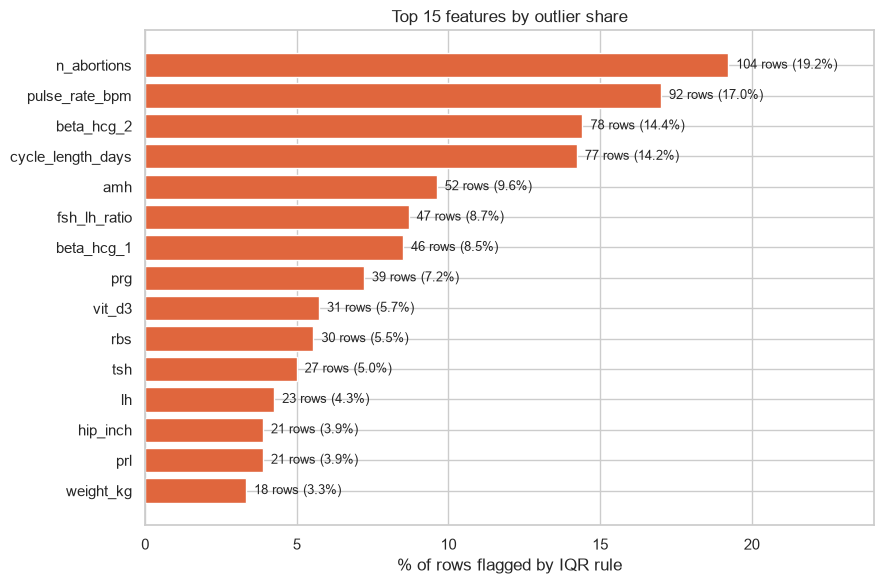

In [10]:
top = out_tbl.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.index, top["iqr_outlier_%"], color="#e0663d")
for i, (v, n) in enumerate(zip(top["iqr_outlier_%"], top["iqr_outliers"])):
    ax.text(v, i, f"  {n} rows ({v:.1f}%)", va="center", fontsize=9)
ax.set_xlabel("% of rows flagged by IQR rule"); ax.set_title("Top 15 features by outlier share")
ax.set_xlim(0, top["iqr_outlier_%"].max() * 1.25)
plt.tight_layout(); savefig("05_outlier_share"); plt.show()

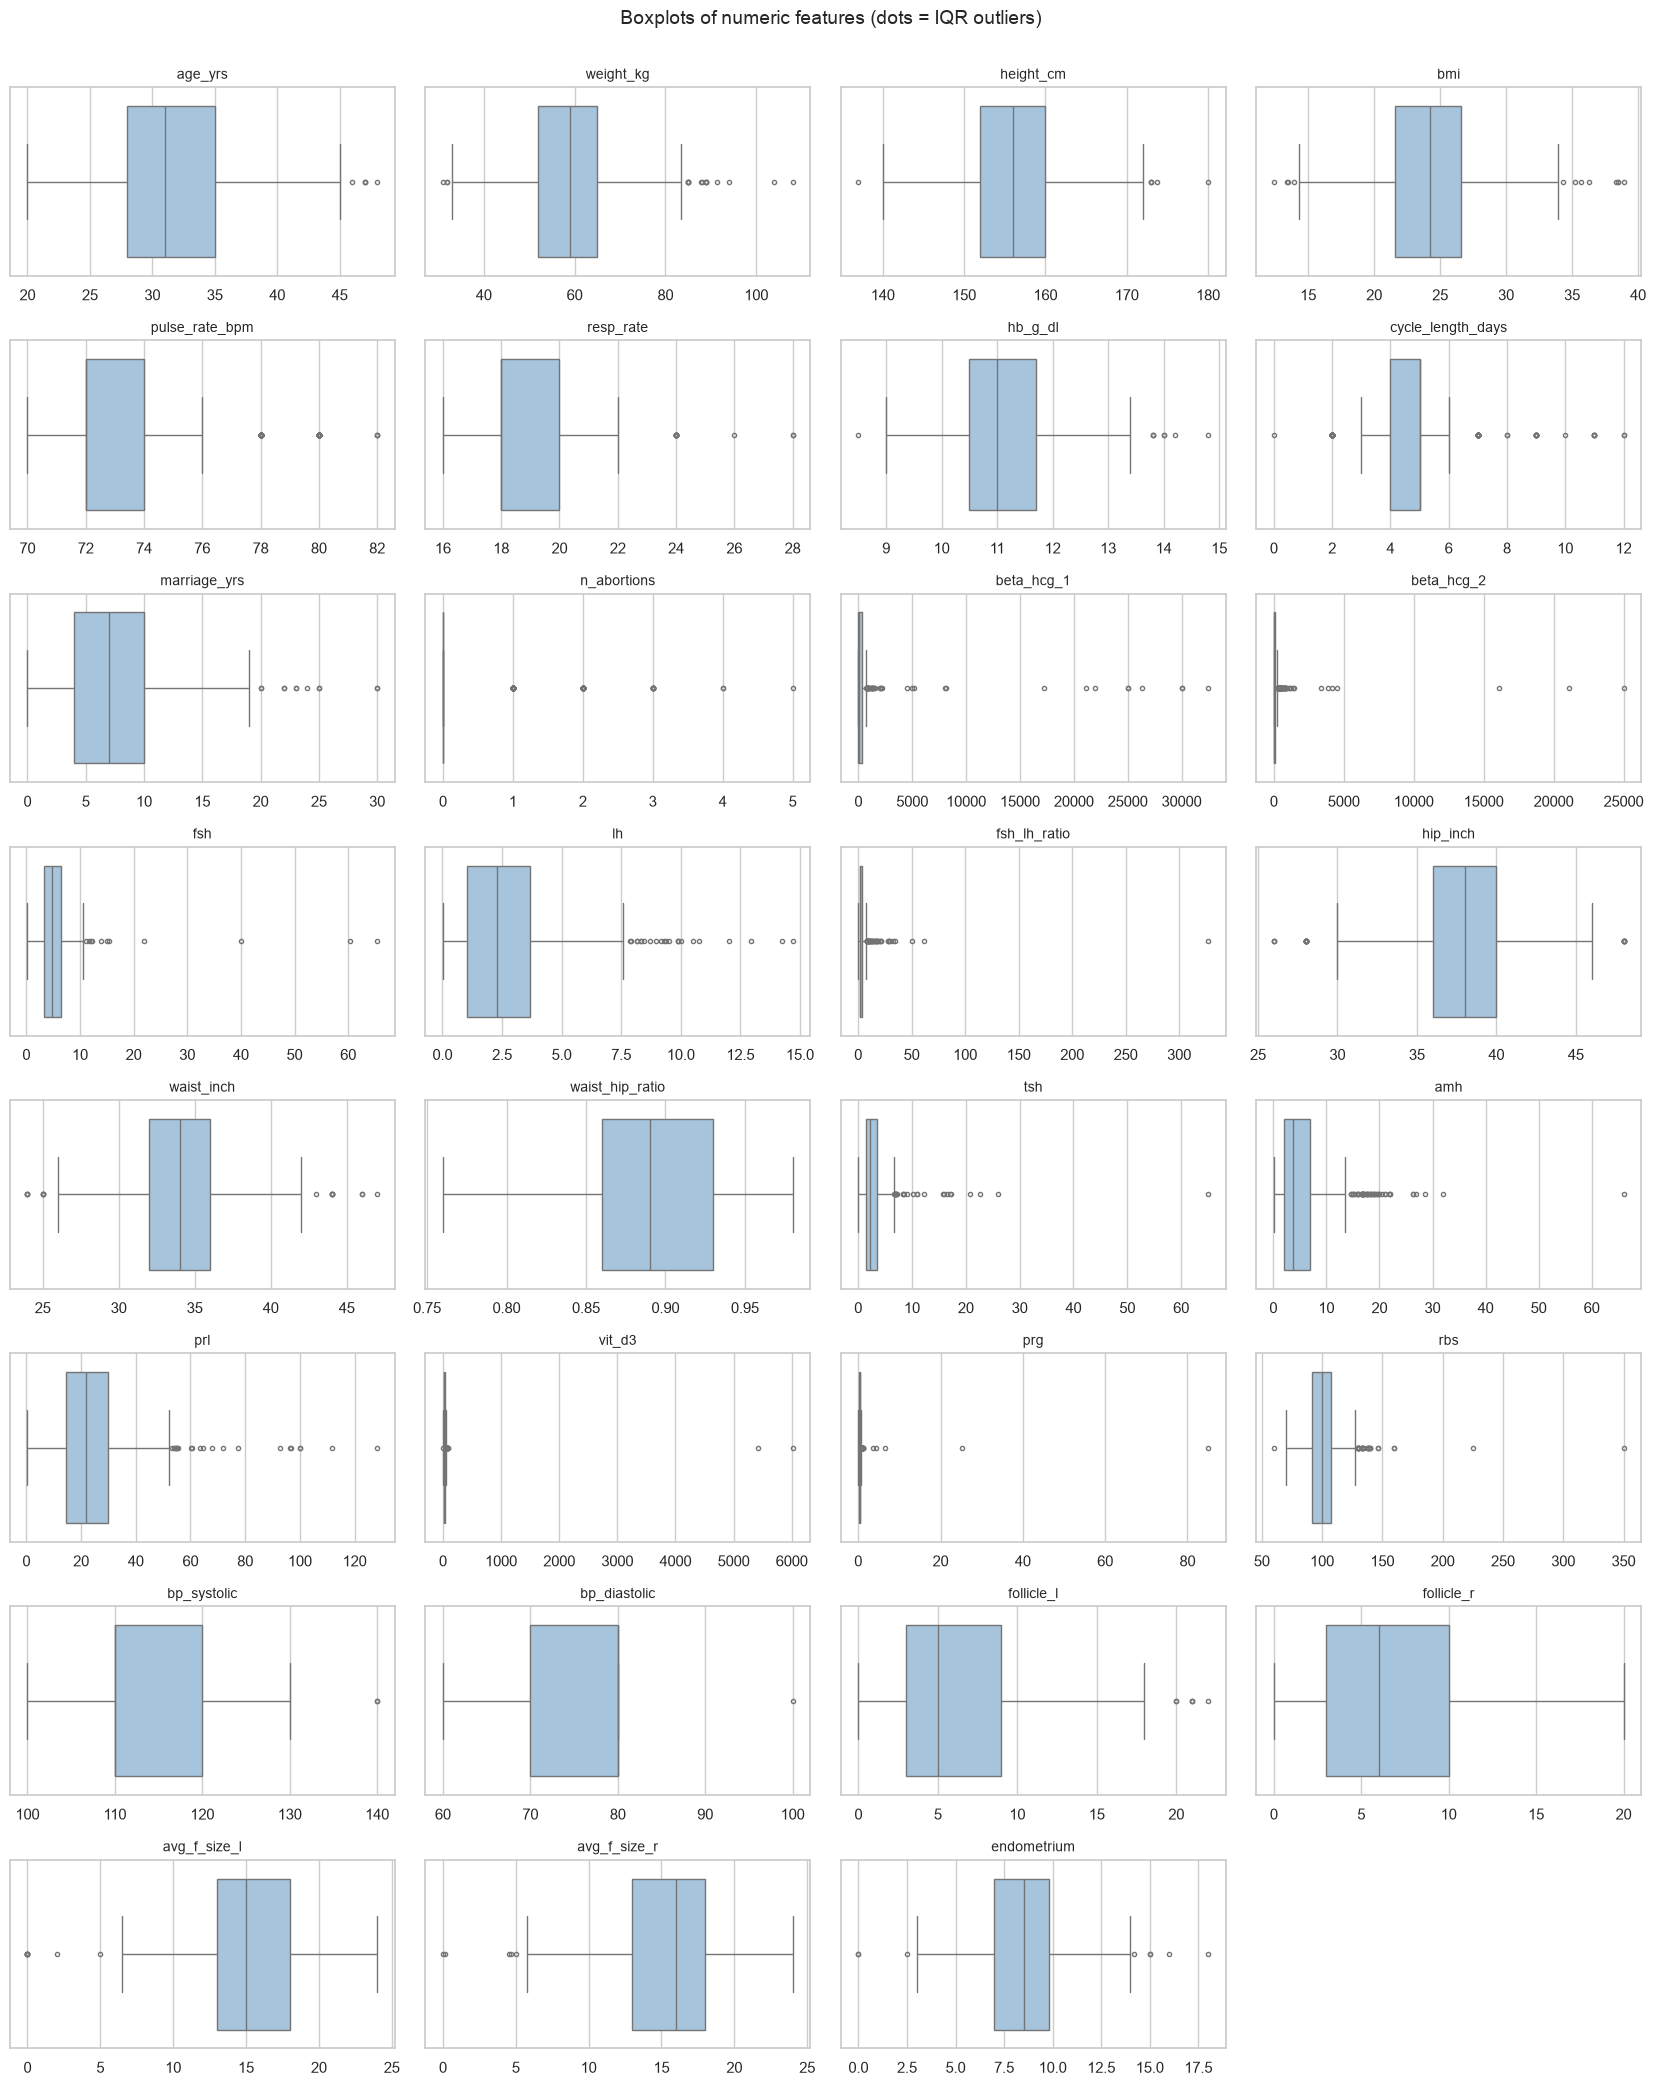

In [11]:
fig, axes = grid(len(num_cols), h=2.6)
for ax, col in zip(axes, num_cols):
    sns.boxplot(x=df[col], color="#9ec5e6", fliersize=3, ax=ax)
    ax.set_title(col, fontsize=10); ax.set_xlabel("")
fig.suptitle("Boxplots of numeric features (dots = IQR outliers)", y=1.002, fontsize=14)
plt.tight_layout(); savefig("06_numeric_boxplots"); plt.show()

In [12]:
# extreme values worth a closer look: the 5 largest |z| per feature, overall
z = df[num_cols].apply(stats.zscore).abs()
extreme = z.stack().sort_values(ascending=False).head(10).reset_index()
extreme.columns = ["row", "feature", "abs_z"]
extreme["value"] = [df.loc[r, f] for r, f in zip(extreme.row, extreme.feature)]
extreme["pcos"] = df.loc[extreme.row, TARGET].values
extreme

,row,feature,abs_z,value,pcos
0,41,prg,22.177,85.000,0
1,250,fsh_lh_ratio,21.673,327.000,1
2,191,vit_d3,17.245,"6,014.660",1
3,37,tsh,16.529,65.000,0
4,195,vit_d3,15.522,"5,418.600",1
5,252,beta_hcg_2,15.453,"25,000.000",1
6,178,rbs,13.492,350.000,1
7,250,fsh,13.418,65.400,1
8,315,beta_hcg_2,13.010,"21,084.210",0
9,281,fsh,12.295,60.370,0


**Decision on outliers:** the impossible readings (pulse < 40, BP 12/8, FSH 5052, LH 2018) were already repaired in notebook 01. For what remains we do **not** remove or cap anything. Reasons:
- The remaining flagged values are plausible clinical extremes (e.g. high AMH, prolactin, β-hCG, vitamin D3 and TSH) — in PCOS these are often exactly the signal.
- The dataset is small (541 rows); dropping rows would hurt more than help.
- Tree-based models are insensitive to outliers, and scaling plus a robust model choice handles the rest for the others.
If model performance later suffers, a log-transform / winsorising step can be added to the training pipeline.

## 7. Binary & categorical features

### 7.1 Distribution and PCOS rate per category

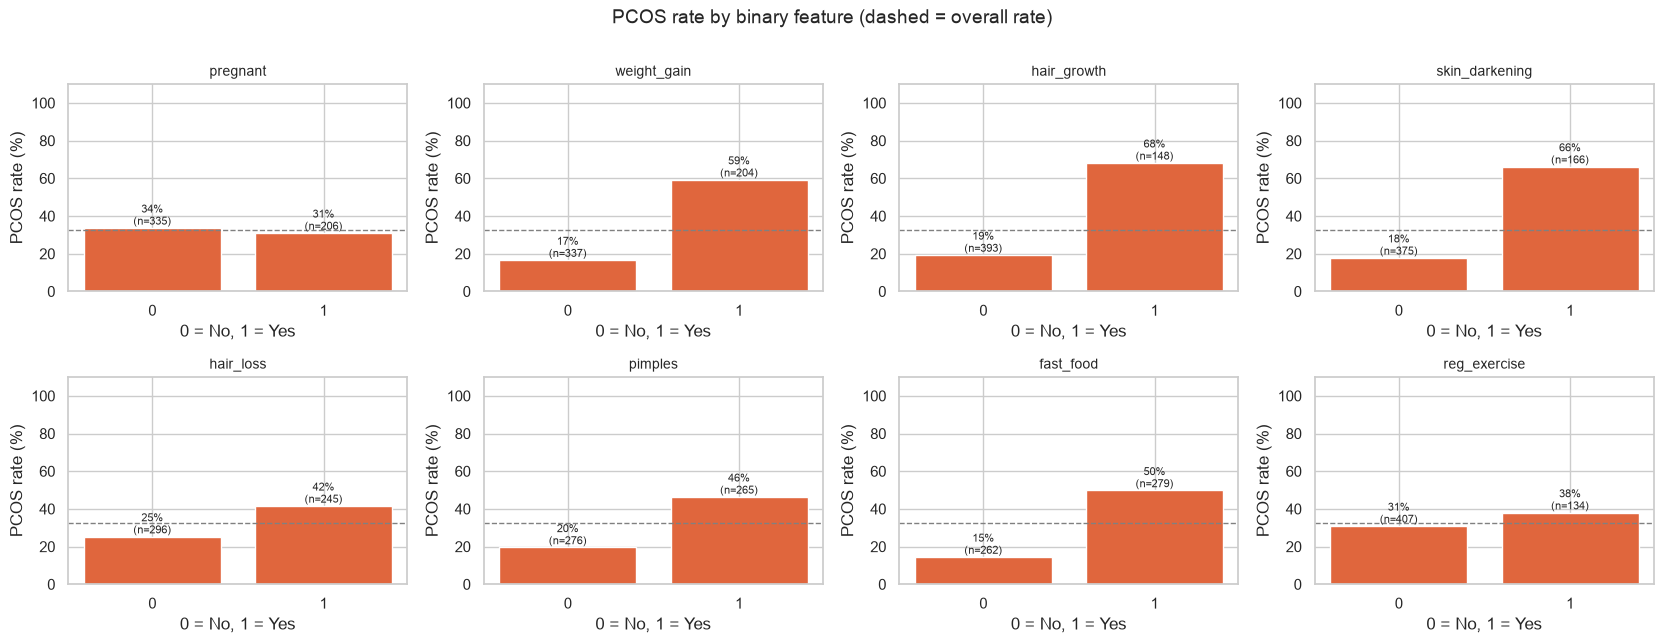

In [13]:
fig, axes = grid(len(binary_cols), ncols=4, h=3.2)
for ax, col in zip(axes, binary_cols):
    rate = df.groupby(col)[TARGET].mean() * 100
    cnt = df[col].value_counts().sort_index()
    bars = ax.bar([str(i) for i in rate.index], rate.values, color="#e0663d")
    for b, n, r in zip(bars, cnt.values, rate.values):
        ax.text(b.get_x() + b.get_width()/2, r, f"{r:.0f}%\n(n={n})", ha="center", va="bottom", fontsize=8)
    ax.set_ylim(0, 110); ax.axhline(df[TARGET].mean()*100, color="grey", ls="--", lw=1)
    ax.set_title(col, fontsize=10); ax.set_ylabel("PCOS rate (%)"); ax.set_xlabel("0 = No, 1 = Yes")
fig.suptitle("PCOS rate by binary feature (dashed = overall rate)", y=1.003, fontsize=14)
plt.tight_layout(); savefig("07_binary_vs_target"); plt.show()

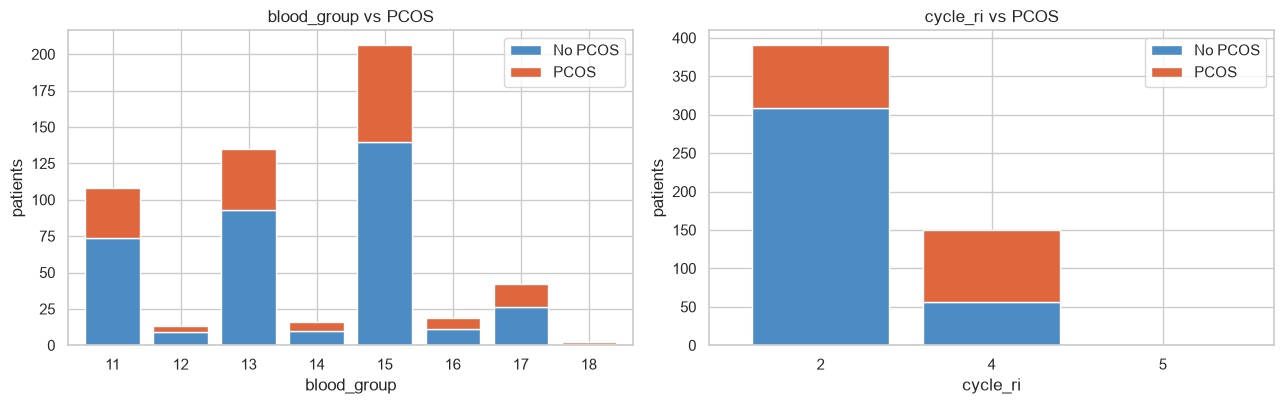

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, col in zip(axes, cat_cols):
    ct = pd.crosstab(df[col], df[TARGET])
    ct.plot(kind="bar", stacked=True, ax=ax, color=[PAL[0], PAL[1]], width=.8)
    ax.legend(["No PCOS", "PCOS"]); ax.set_title(f"{col} vs PCOS"); ax.set_ylabel("patients"); ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); savefig("08_categorical_vs_target"); plt.show()

In [15]:
# chi-square: is each binary/categorical feature associated with the target?
rows = []
for col in binary_cols + cat_cols:
    chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(df[col], df[TARGET]))
    n = len(df); k = min(pd.crosstab(df[col], df[TARGET]).shape) - 1
    rows.append({"feature": col, "chi2": chi2, "p_value": p, "cramers_v": np.sqrt(chi2 / (n * k)), "significant(p<.05)": p < .05})
pd.DataFrame(rows).sort_values("p_value").set_index("feature")

,chi2,p_value,cramers_v,significant(p<.05)
feature,,,,
skin_darkening,120.251,0.000,0.471,True
hair_growth,114.599,0.000,0.460,True
weight_gain,103.306,0.000,0.437,True
cycle_ri,87.395,0.000,0.402,True
fast_food,74.963,0.000,0.372,True
pimples,43.064,0.000,0.282,True
hair_loss,15.437,0.000,0.169,True
reg_exercise,1.998,0.157,0.061,False
pregnant,0.299,0.585,0.024,False


## 8. Numeric features vs target

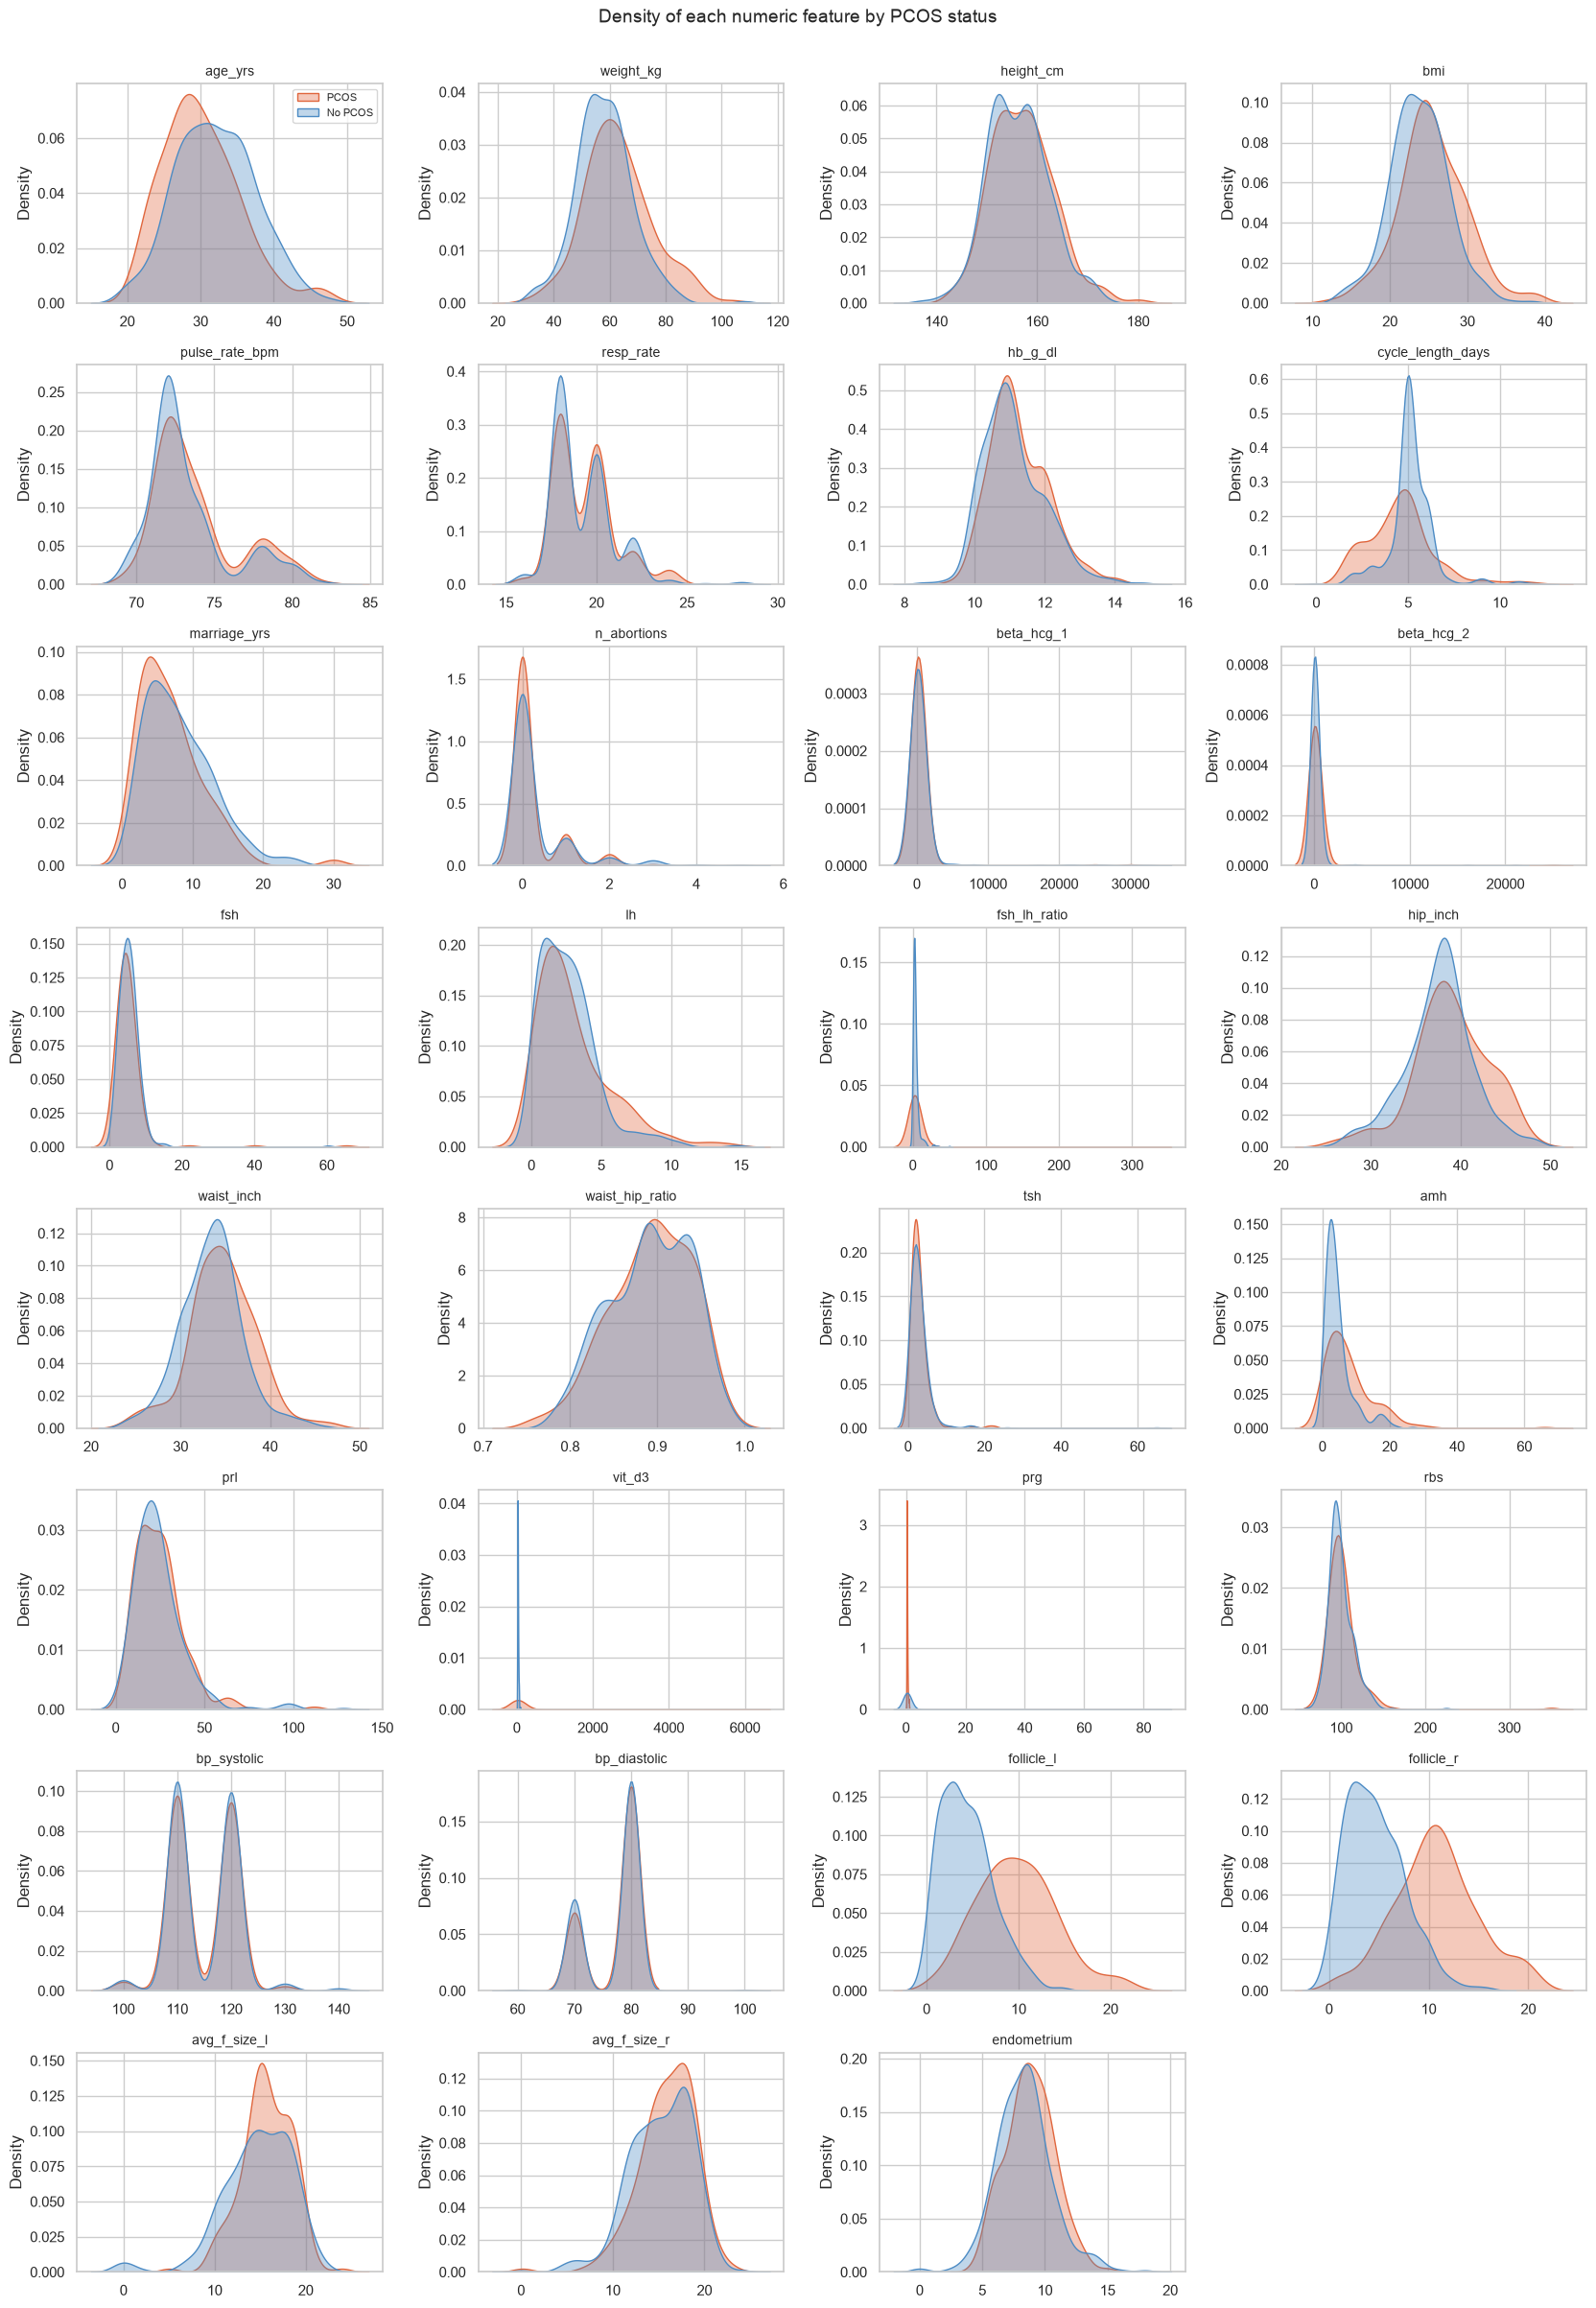

In [16]:
fig, axes = grid(len(num_cols), h=3.0)
for ax, col in zip(axes, num_cols):
    sns.kdeplot(data=df, x=col, hue=TARGET, palette=PAL, common_norm=False, fill=True, alpha=.35, ax=ax, legend=False)
    ax.set_title(col, fontsize=10); ax.set_xlabel("")
axes[0].legend(["PCOS", "No PCOS"], fontsize=8)
fig.suptitle("Density of each numeric feature by PCOS status", y=1.002, fontsize=14)
plt.tight_layout(); savefig("09_numeric_kde_by_target"); plt.show()

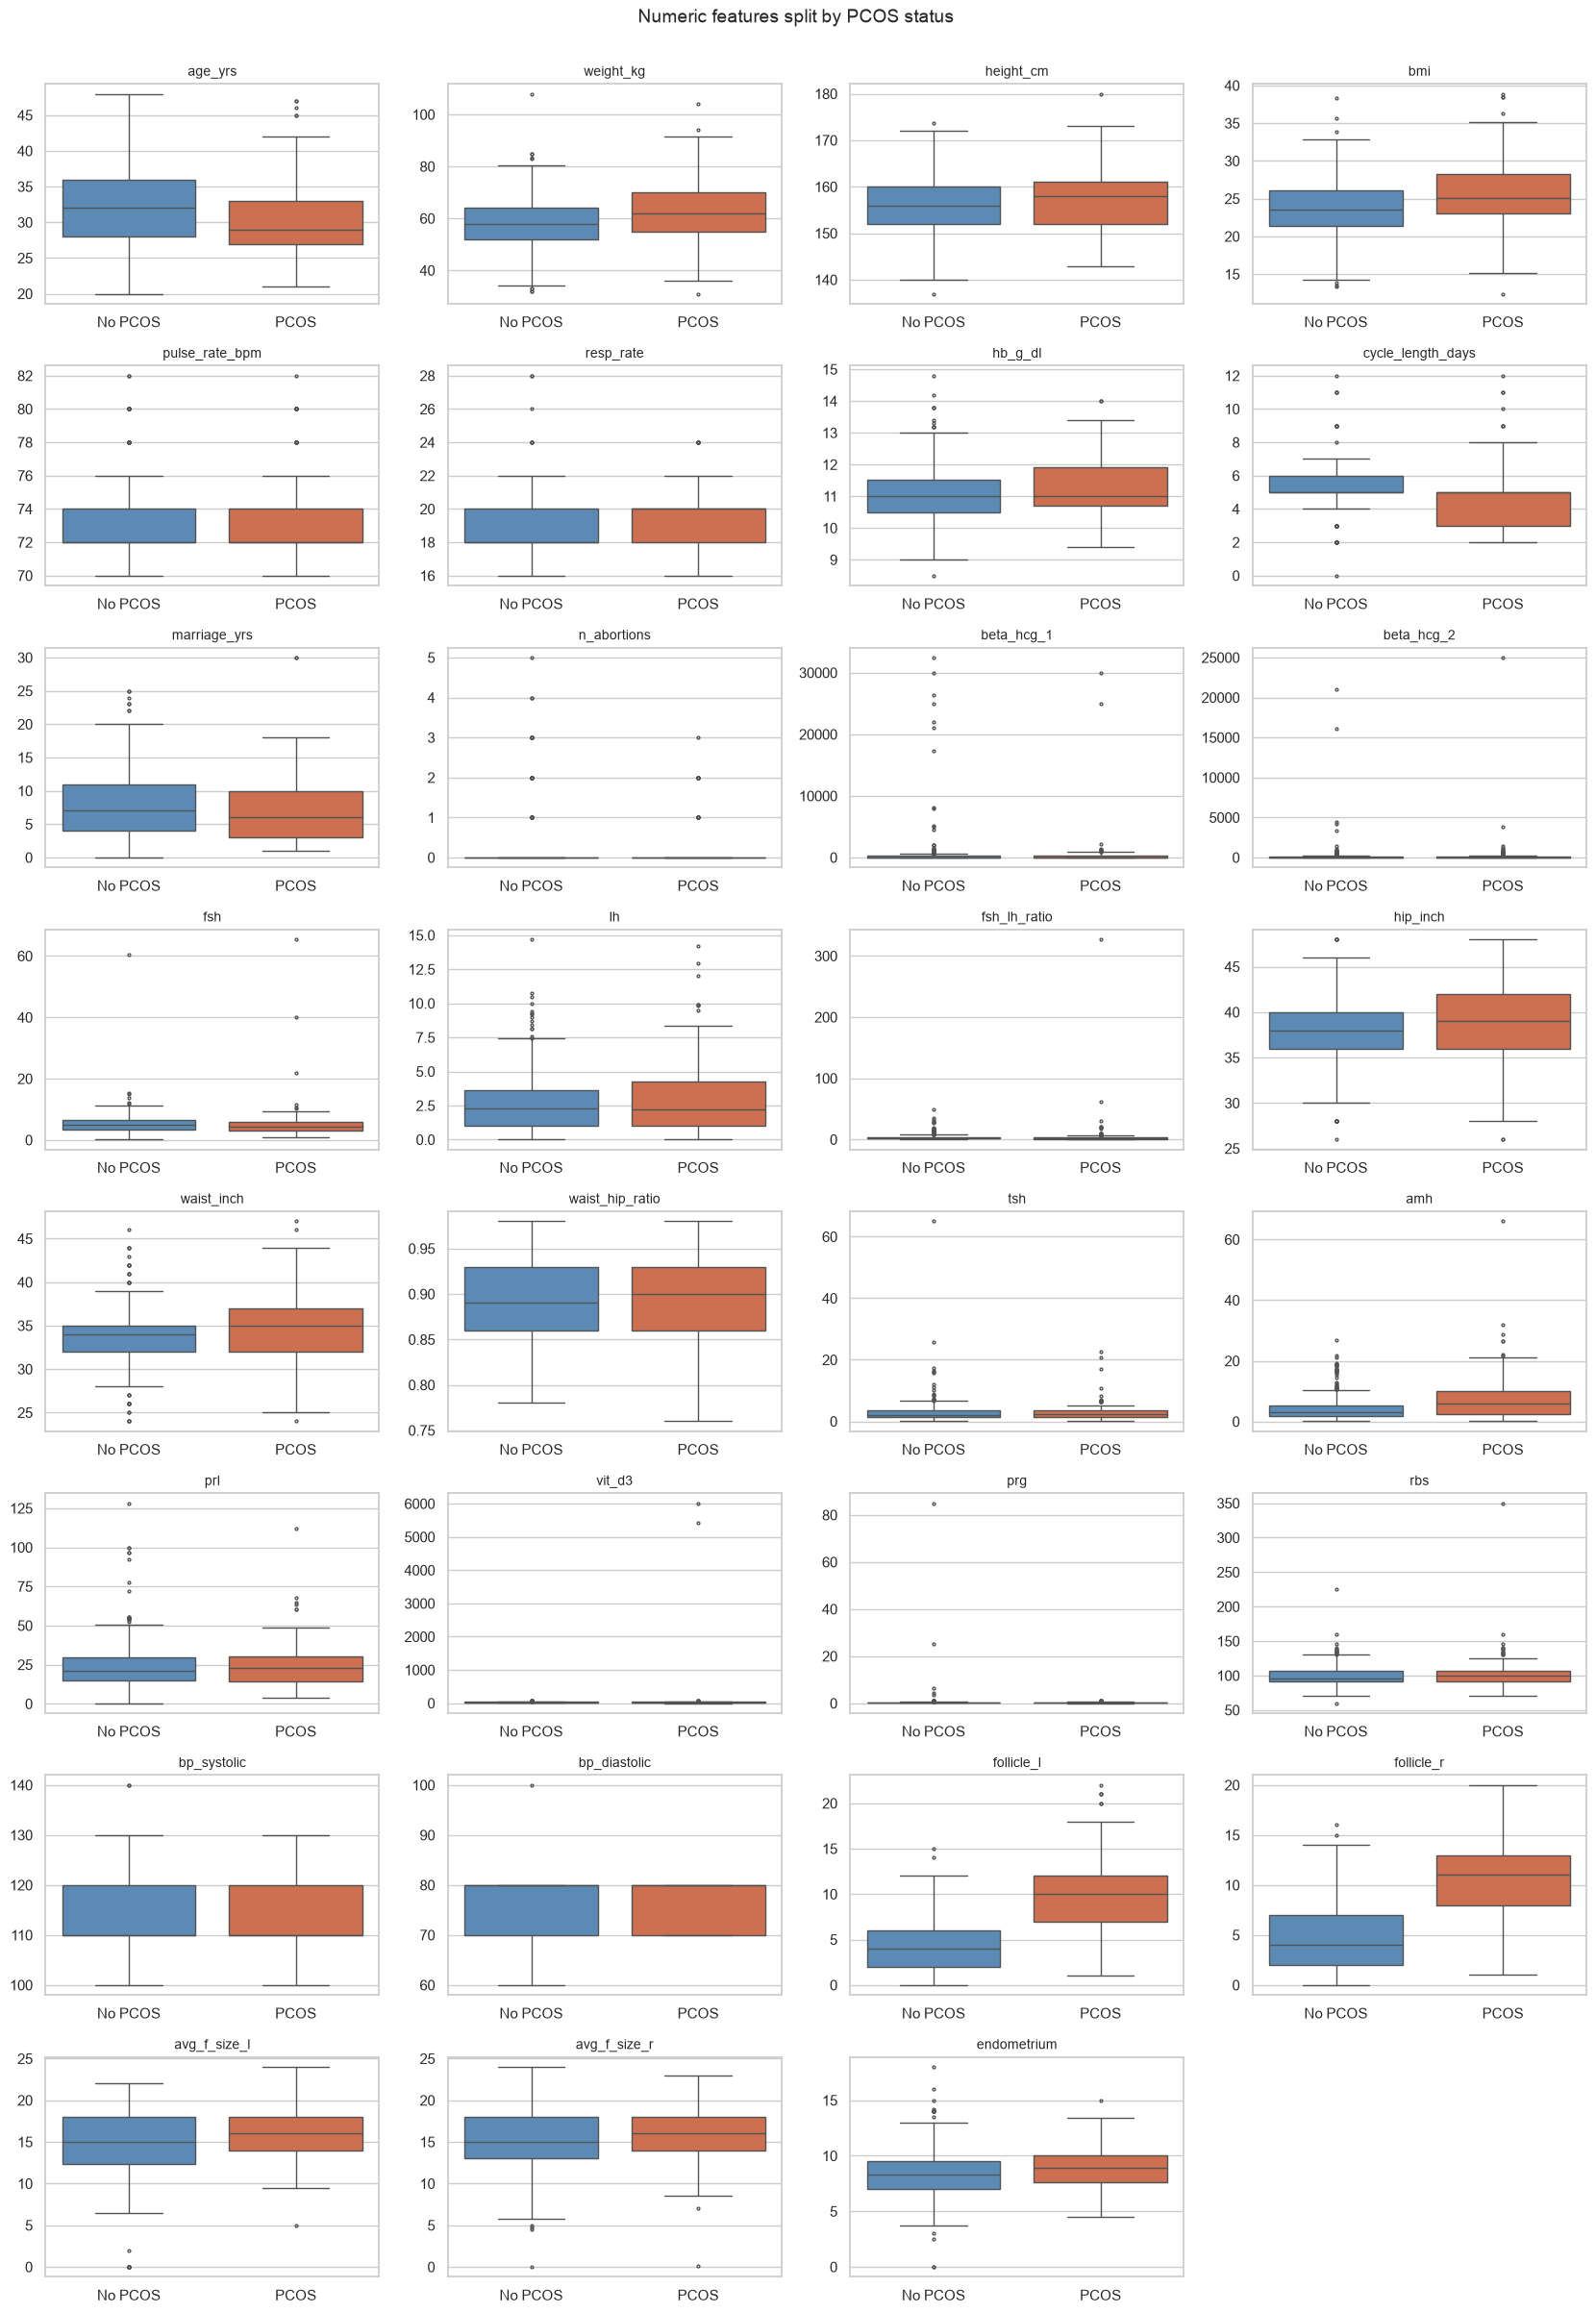

In [17]:
fig, axes = grid(len(num_cols), h=3.0)
for ax, col in zip(axes, num_cols):
    sns.boxplot(data=df, x=TARGET, y=col, palette=[PAL[0], PAL[1]], ax=ax, fliersize=2)
    ax.set_xticklabels(["No PCOS", "PCOS"]); ax.set_xlabel(""); ax.set_title(col, fontsize=10); ax.set_ylabel("")
fig.suptitle("Numeric features split by PCOS status", y=1.002, fontsize=14)
plt.tight_layout(); savefig("10_numeric_box_by_target"); plt.show()

In [18]:
# statistical test per numeric feature (Mann-Whitney U: no normality assumption)
rows = []
for col in num_cols:
    a, b = df.loc[df[TARGET] == 0, col], df.loc[df[TARGET] == 1, col]
    u, p = stats.mannwhitneyu(a, b)
    rows.append({"feature": col, "mean_no_pcos": a.mean(), "mean_pcos": b.mean(),
                 "median_no_pcos": a.median(), "median_pcos": b.median(),
                 "diff_%": (b.mean() - a.mean()) / abs(a.mean()) * 100 if a.mean() else np.nan,
                 "p_value": p, "significant(p<.05)": p < .05})
mw = pd.DataFrame(rows).sort_values("p_value").set_index("feature")
mw

,mean_no_pcos,mean_pcos,median_no_pcos,median_pcos,diff_%,p_value,significant(p<.05)
feature,,,,,,,
follicle_r,4.637,10.763,4.000,11.000,132.087,0.000,True
follicle_l,4.352,9.785,4.000,10.000,124.864,0.000,True
cycle_length_days,5.126,4.559,5.000,5.000,-11.061,0.000,True
amh,4.539,7.845,3.210,5.900,72.820,0.000,True
bmi,23.743,25.468,23.600,25.100,7.263,0.000,True
weight_kg,58.009,62.986,58.000,62.000,8.580,0.000,True
age_yrs,32.066,30.124,32.000,29.000,-6.055,0.000,True
waist_inch,33.429,34.689,34.000,35.000,3.771,0.000,True
hip_inch,37.544,38.915,38.000,39.000,3.653,0.000,True


## 9. Correlation analysis

### 9.1 Correlation of each feature with the target

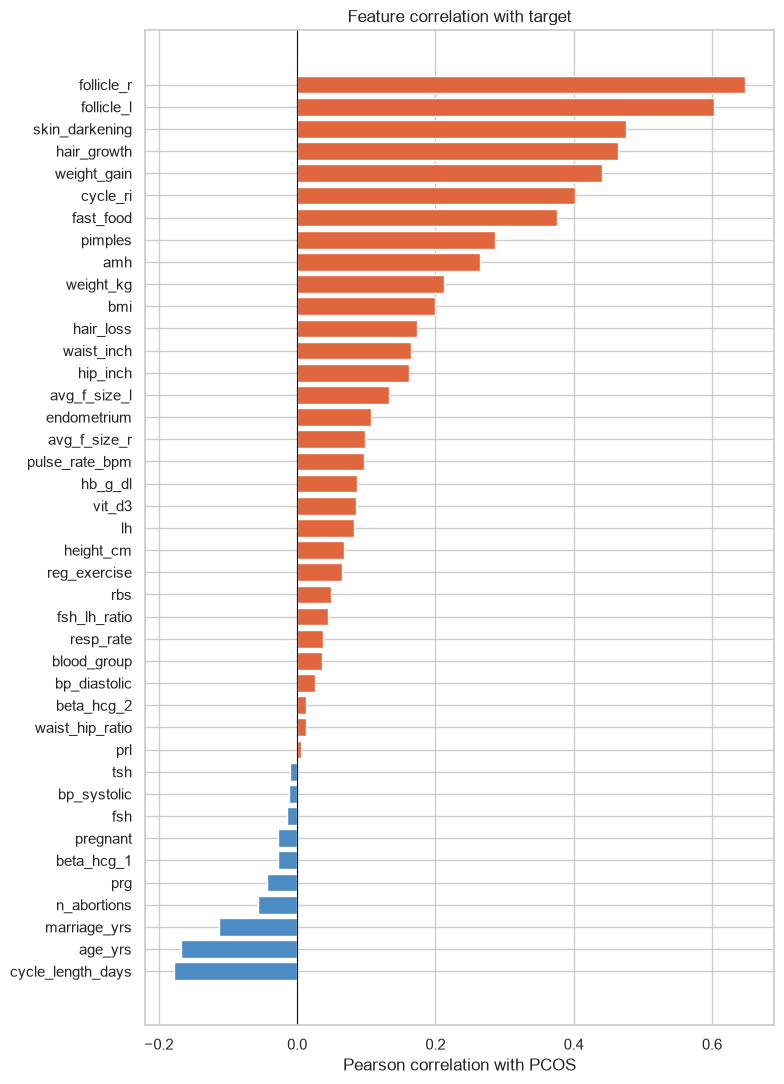

Top 10 by |correlation|:
follicle_r       0.648
follicle_l       0.603
skin_darkening   0.476
hair_growth      0.465
weight_gain      0.441
cycle_ri         0.402
fast_food        0.376
pimples          0.286
amh              0.264
weight_kg        0.212


In [19]:
corr_t = df.corr()[TARGET].drop(TARGET).sort_values()
fig, ax = plt.subplots(figsize=(8, 11))
colors = [PAL[1] if v > 0 else PAL[0] for v in corr_t.values]
ax.barh(corr_t.index, corr_t.values, color=colors)
ax.axvline(0, color="k", lw=.8); ax.set_xlabel("Pearson correlation with PCOS")
ax.set_title("Feature correlation with target")
plt.tight_layout(); savefig("11_corr_with_target"); plt.show()
print("Top 10 by |correlation|:"); print(corr_t.reindex(corr_t.abs().sort_values(ascending=False).index).head(10).round(3).to_string())

### 9.2 Feature-to-feature correlation (multicollinearity)

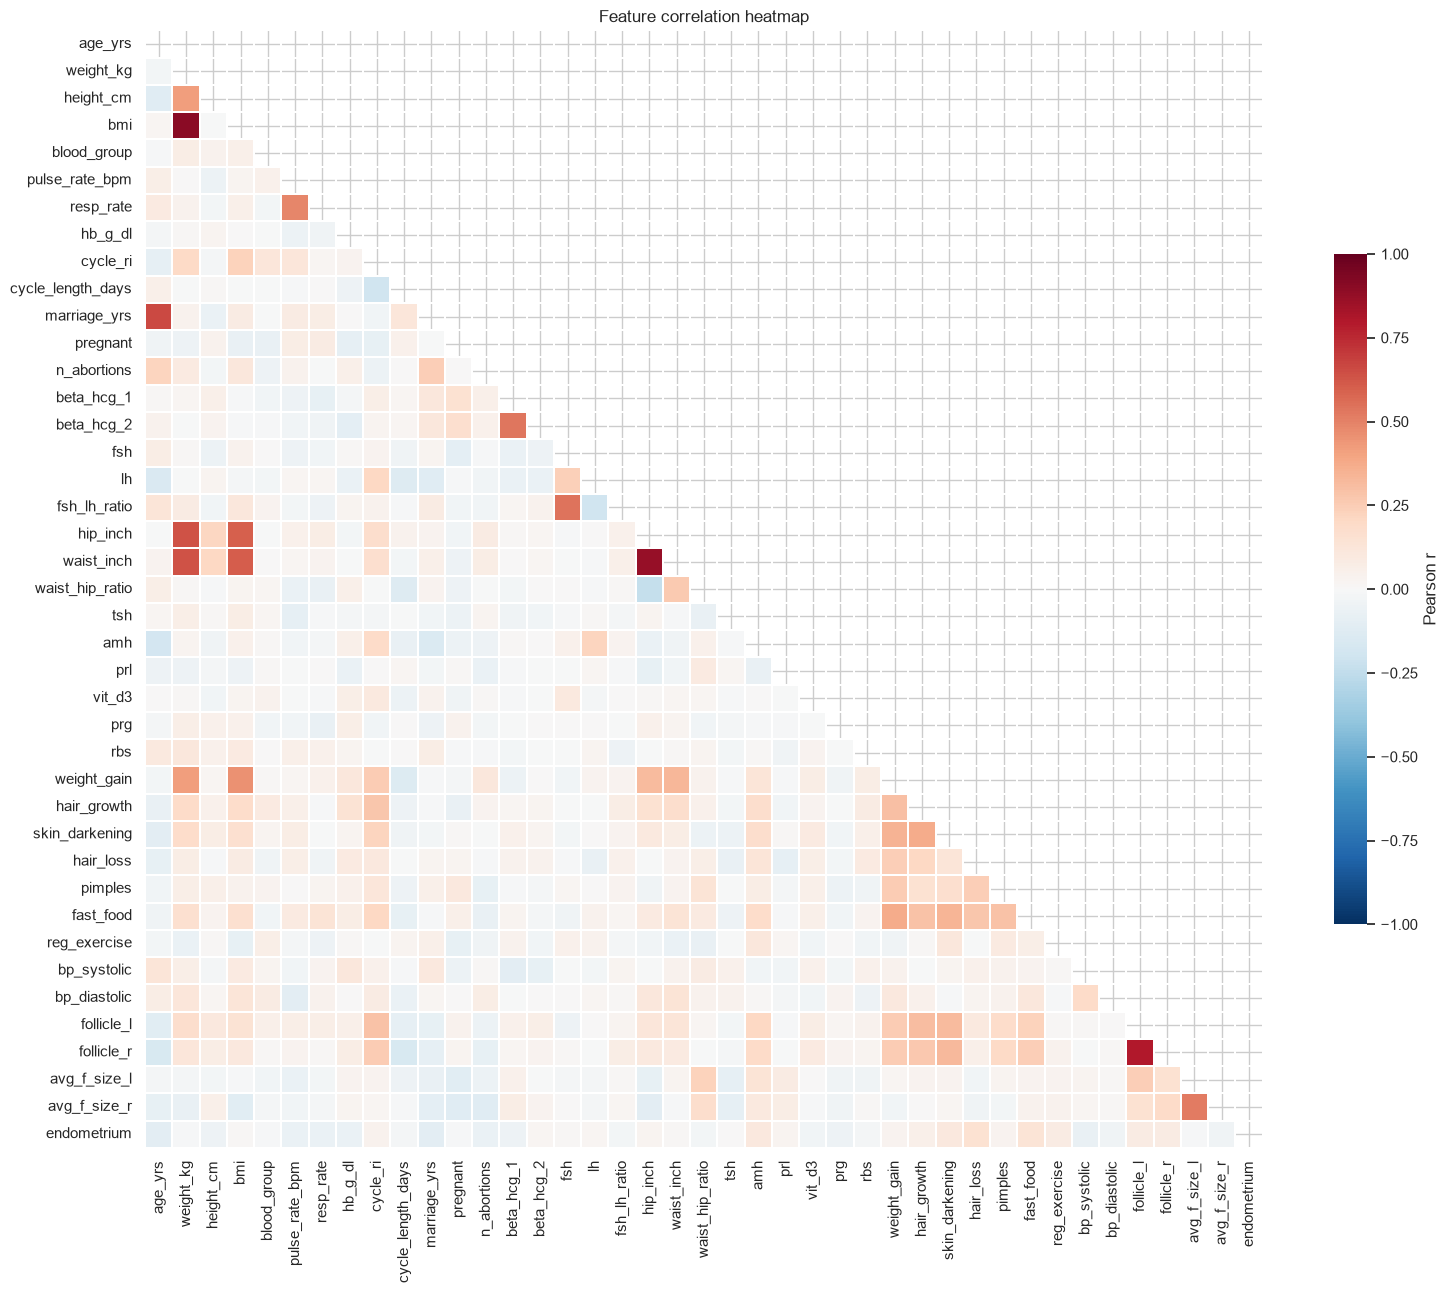

In [20]:
corr = df.drop(columns=TARGET).corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(16, 13))
sns.heatmap(corr, mask=mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True, linewidths=.3,
            cbar_kws={"shrink": .6, "label": "Pearson r"}, ax=ax)
ax.set_title("Feature correlation heatmap")
plt.tight_layout(); savefig("12_correlation_heatmap"); plt.show()

In [21]:
pairs = corr.where(~mask).stack().rename("r").reset_index()
pairs.columns = ["feature_1", "feature_2", "r"]
pairs["abs_r"] = pairs.r.abs()
high = pairs[pairs.abs_r >= 0.7].sort_values("abs_r", ascending=False)
print(f"{len(high)} feature pairs with |r| >= 0.7 (potential redundancy):")
high.drop(columns="abs_r").reset_index(drop=True)

3 feature pairs with |r| >= 0.7 (potential redundancy):


,feature_1,feature_2,r
0,bmi,weight_kg,0.902
1,waist_inch,hip_inch,0.873
2,follicle_r,follicle_l,0.800


**Takeaway:** strongly correlated pairs are mostly *derived* variables (weight/BMI, hip/waist, FSH & LH with FSH/LH, left/right follicle counts).
This matters for Logistic Regression (unstable coefficients) and Naive Bayes (assumes independence). Tree models don't mind.

## 10. Key predictors in detail

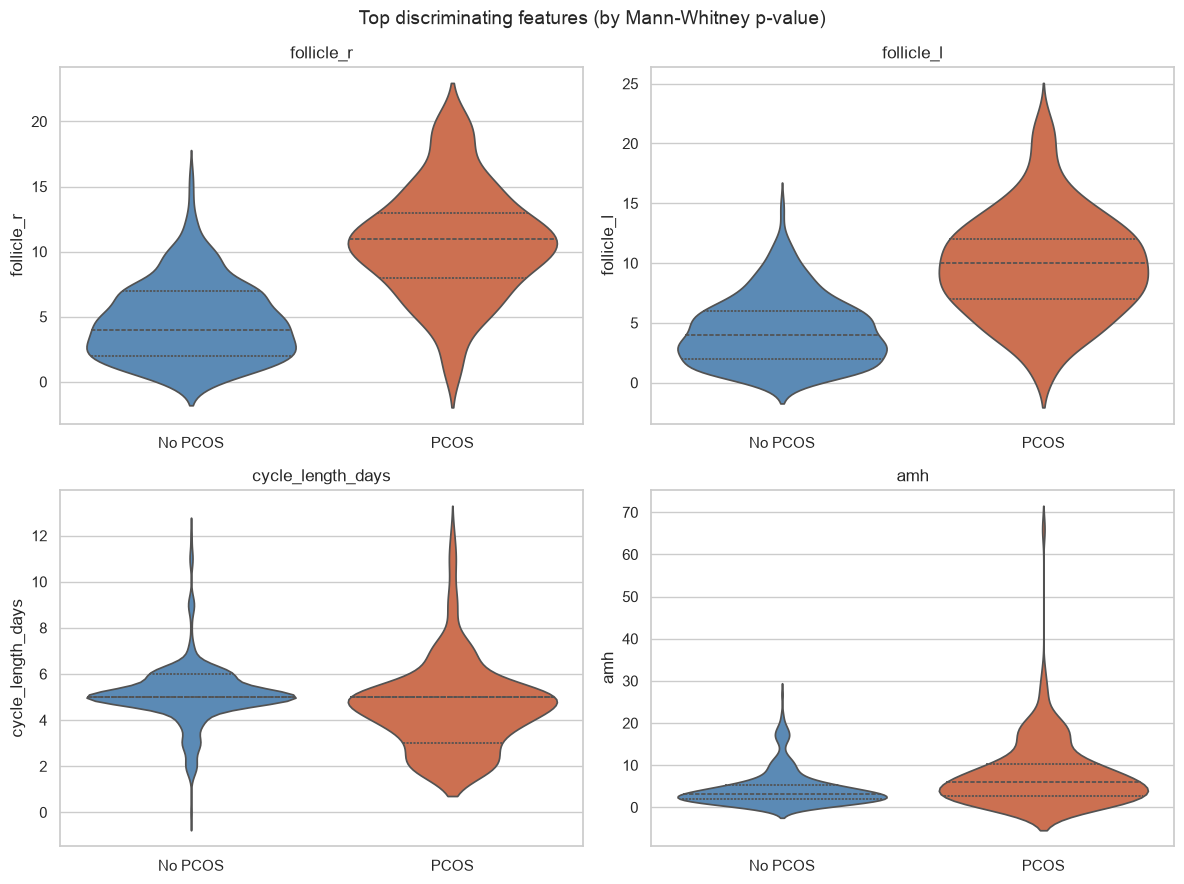

In [22]:
top_feats = list(mw.index[:4]) + [c for c in ["bmi"] if c not in mw.index[:4]]
top_feats = top_feats[:4]
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, col in zip(axes.ravel(), top_feats):
    sns.violinplot(data=df, x=TARGET, y=col, palette=[PAL[0], PAL[1]], inner="quartile", ax=ax)
    ax.set_xticklabels(["No PCOS", "PCOS"]); ax.set_xlabel(""); ax.set_title(col)
fig.suptitle("Top discriminating features (by Mann-Whitney p-value)", fontsize=14)
plt.tight_layout(); savefig("13_top_features_violin"); plt.show()

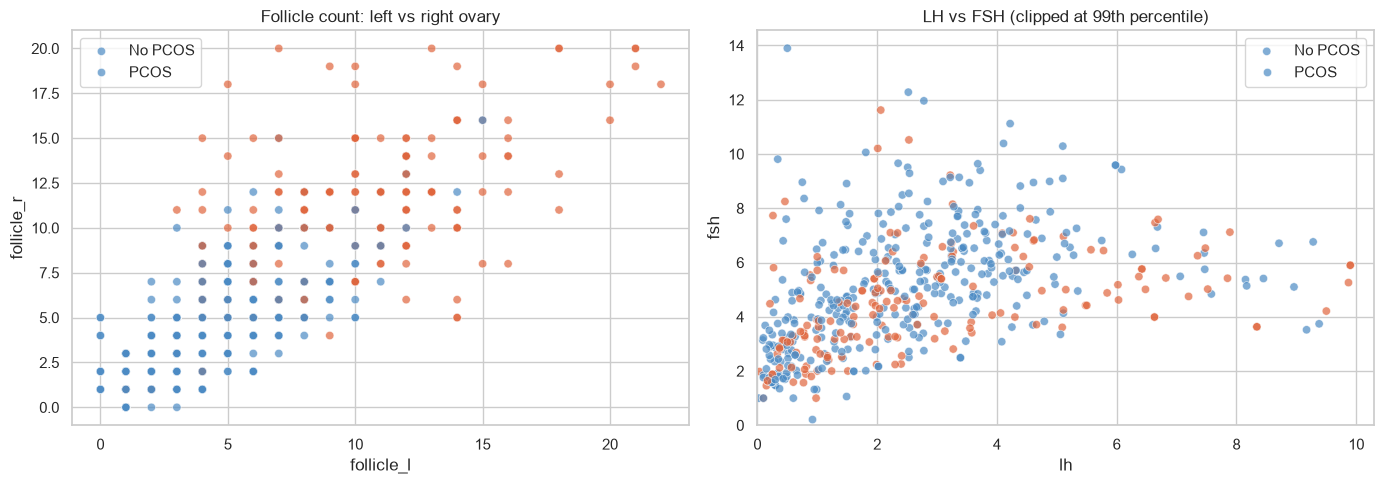

In [23]:
f1, f2 = "follicle_l", "follicle_r"
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=df, x=f1, y=f2, hue=TARGET, palette=PAL, alpha=.7, ax=axes[0])
axes[0].set_title("Follicle count: left vs right ovary"); axes[0].legend(title="", labels=["No PCOS", "PCOS"])
sns.scatterplot(data=df, x="lh", y="fsh", hue=TARGET, palette=PAL, alpha=.7, ax=axes[1])
axes[1].set_xlim(0, df.lh.quantile(.99)); axes[1].set_ylim(0, df.fsh.quantile(.99))
axes[1].set_title("LH vs FSH (clipped at 99th percentile)"); axes[1].legend(title="", labels=["No PCOS", "PCOS"])
plt.tight_layout(); savefig("14_scatter_key_pairs"); plt.show()

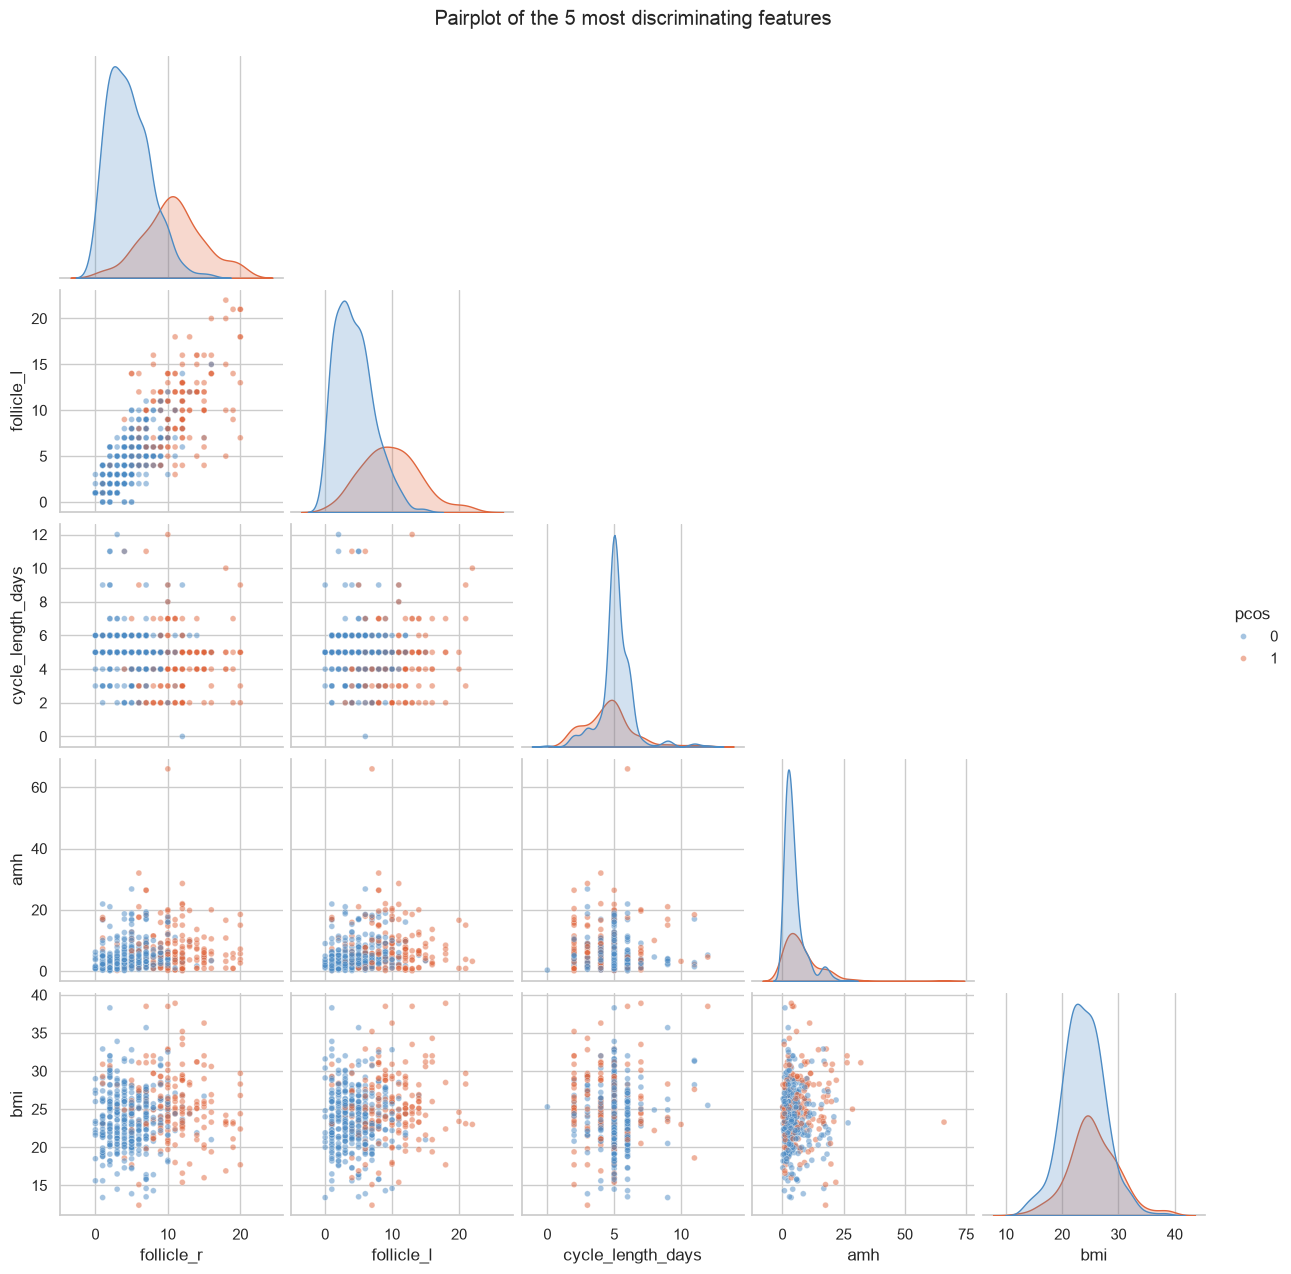

In [24]:
sel = list(mw.index[:5]) + [TARGET]
g = sns.pairplot(df[sel], hue=TARGET, palette=PAL, corner=True, plot_kws={"alpha": .5, "s": 18}, diag_kind="kde")
g.figure.suptitle("Pairplot of the 5 most discriminating features", y=1.02)
g.savefig(FIG / "15_pairplot_top_features.png", dpi=130, bbox_inches="tight"); plt.show()

## 11. Key findings & modelling implications

| # | Finding | Implication for modelling |
|---|---|---|
| 1 | 541 patients, 41 features, target is binary with ≈ 33 % positives | Use **stratified** train/test split; report AUC, F1, MCC alongside accuracy |
| 2 | Only 4 cells were missing (fixed in notebook 01) | No imputation burden; but keep the same imputer logic for new uploads |
| 3 | Hormone/lab features are right-skewed with real extreme values | **Scale** features (StandardScaler) for LR / KNN / SVM; keep outliers |
| 4 | Follicle counts, follicle sizes and symptoms (weight gain, hair growth, skin darkening, irregular cycle) differ most between PCOS / non-PCOS | Expect strong performance; these are the dominant signals |
| 5 | Many correlated/derived features (BMI, waist:hip, FSH/LH) | Watch collinearity for LR/Naive Bayes; trees unaffected |
| 6 | Ultrasound features are part of the diagnostic criteria | Possible target leakage in a clinical sense — mention in README |

**Next:** build `src/train.py` — preprocessing pipeline, 5 classifiers, 6 metrics, save models to `model/`, export `test_data.csv`.